In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evaluation.py').exists())
path = ROOT / 'data'
figs = ROOT / 'figures'; figs.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

KEY = ['Equity/total_assets', 'EBITDA/total_assets',
       'Current_assets/short_term_liabilities', 'Net_profit/total_assets']

,horizon,rows,distressed,rate_%
0,0y,1000087,3587,0.358669
1,1y,996500,3054,0.306473
2,2y,898692,2374,0.264162
3,3y,793234,1896,0.239022
4,4y,700041,1485,0.212130
5,5y,598832,1154,0.192708


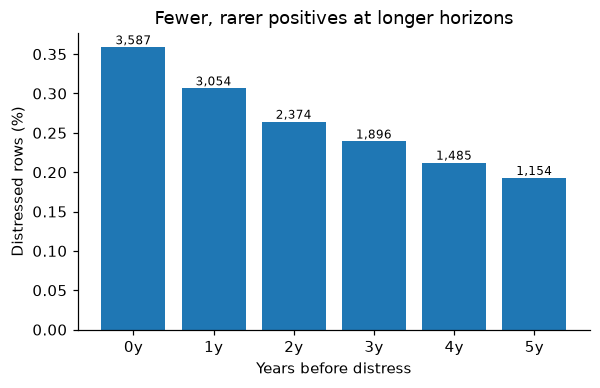

In [4]:
rows = []
for h in range(1, 7):
    y = pd.read_parquet(path/f'company_years_h{h}.parquet', columns=['main_label']).main_label
    rows.append({'horizon': f'{h-1}y', 'rows': len(y), 'distressed': int(y.sum()), 'rate_%': 100 * y.mean()})
bal = pd.DataFrame(rows); display(bal)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(bal.horizon, bal['rate_%'])
for i, r in bal.iterrows():
    ax.text(i, r['rate_%'], f"{r.distressed:,}", ha='center', va='bottom', fontsize=8)
ax.set(xlabel='Years before distress', ylabel='Distressed rows (%)',
       title='Fewer, rarer positives at longer horizons')
plt.savefig(figs/'fig1_class_balance.png', bbox_inches='tight'); plt.show()

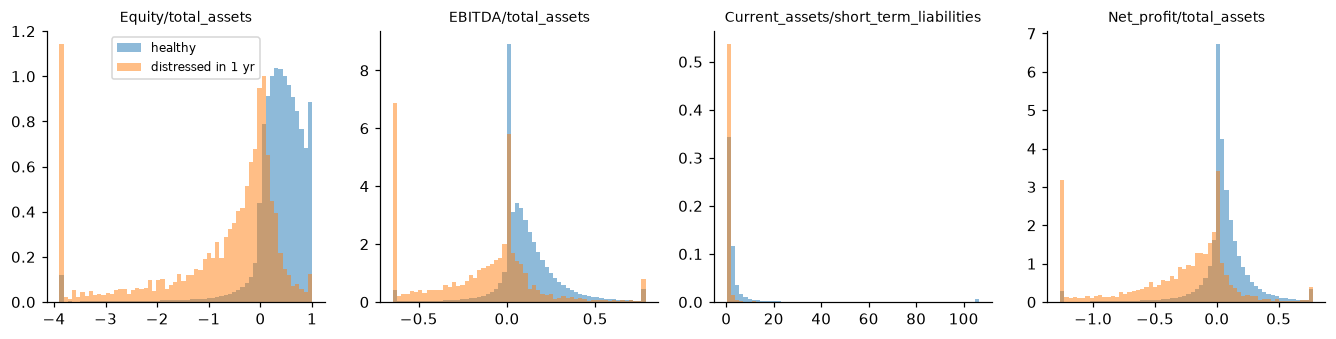

In [6]:
df = pd.read_parquet(path/'company_years_h2.parquet', columns=KEY + ['main_label'])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, KEY):
    lo, hi = df[col].quantile([0.01, 0.99])
    for lab, name in [(0, 'healthy'), (1, 'distressed in 1 yr')]:
        ax.hist(df.loc[df.main_label == lab, col].clip(lo, hi).dropna(),
                bins=60, density=True, alpha=0.5, label=name)
    ax.set_title(col, fontsize=9)
axes[0].legend(fontsize=8)
plt.savefig(figs/'fig2_distributions.png', bbox_inches='tight'); plt.show()

In [7]:
# Cell 4: when did each distressed firm hit distress?
h0 = pd.read_parquet(path/'company_years_h1.parquet', columns=['company', 'year', 'main_label'])
distress_year = h0.loc[h0.main_label == 1].set_index('company').year.rename('distress_year')

panel = pd.read_parquet(path/'company_years.parquet', columns=['company', 'year'] + KEY)
d = panel.join(distress_year, on='company', how='inner')          # distressed firms only
d['years_before'] = d.distress_year - d.year
d = d[d.years_before.between(0, 5)]

healthy = panel[~panel.company.isin(distress_year.index)]          # firms never distressed
print(f"distressed firms: {len(distress_year):,}, rows used: {len(d):,}")

distressed firms: 3,587, rows used: 12,182


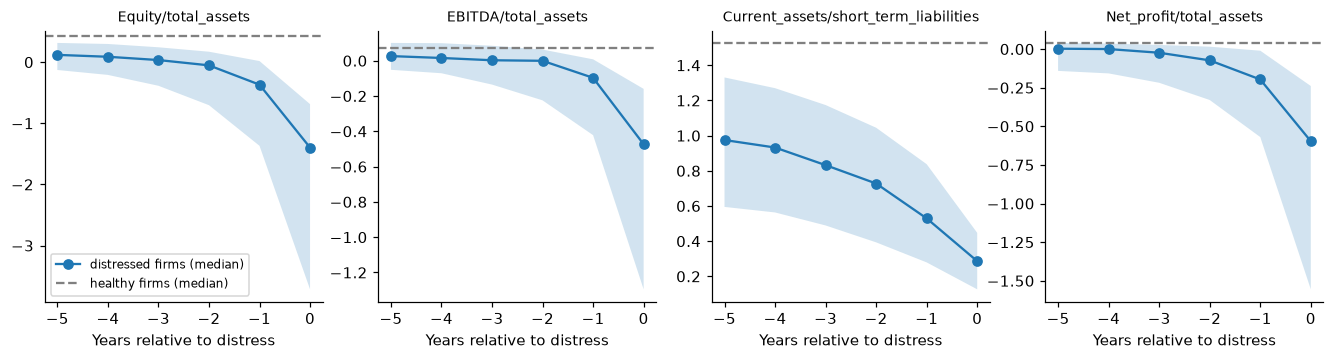

In [8]:
# Cell 5: plot
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, KEY):
    g = d.groupby('years_before')[col]
    med, q25, q75 = g.median(), g.quantile(0.25), g.quantile(0.75)
    x = -med.index
    ax.plot(x, med, marker='o', label='distressed firms (median)')
    ax.fill_between(x, q25, q75, alpha=0.2)
    ax.axhline(healthy[col].median(), ls='--', color='grey', label='healthy firms (median)')
    ax.set(title=col, xlabel='Years relative to distress')
    ax.title.set_fontsize(9)
axes[0].legend(fontsize=8)
plt.savefig(figs/'fig3_deterioration.png', bbox_inches='tight'); plt.show()

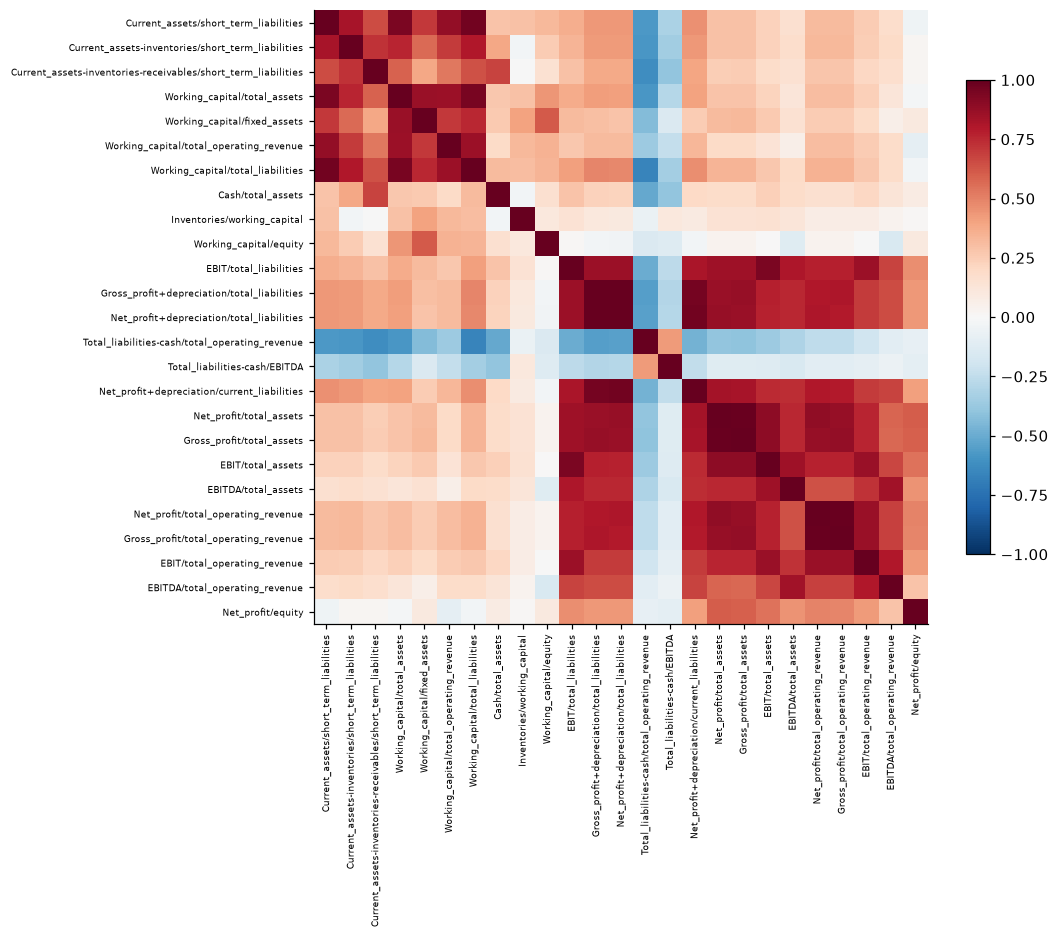

Gross_profit+depreciation/total_liabilities  Net_profit+depreciation/total_liabilities      0.992657
Net_profit/total_assets                      Gross_profit/total_assets                      0.989026
Net_profit/total_operating_revenue           Gross_profit/total_operating_revenue           0.986861
Net_profit+depreciation/total_liabilities    Net_profit+depreciation/current_liabilities    0.964905
Current_assets/short_term_liabilities        Working_capital/total_liabilities              0.962834
Gross_profit+depreciation/total_liabilities  Net_profit+depreciation/current_liabilities    0.956163
Working_capital/total_assets                 Working_capital/total_liabilities              0.948850
EBIT/total_liabilities                       EBIT/total_assets                              0.941772
Current_assets/short_term_liabilities        Working_capital/total_assets                   0.939929
dtype: float64

In [9]:
full = pd.read_parquet(path/'company_years_h2.parquet').sample(200_000, random_state=42)
ratio_cols = [c for c in full.select_dtypes('number').columns
              if '/' in c and full[c].notna().mean() > 0.5][:25]
corr = full[ratio_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(ratio_cols))); ax.set_xticklabels(ratio_cols, rotation=90, fontsize=6)
ax.set_yticks(range(len(ratio_cols))); ax.set_yticklabels(ratio_cols, fontsize=6)
plt.colorbar(im, shrink=0.7)
plt.savefig(figs/'fig4_correlations.png', bbox_inches='tight'); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
display(pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False))